<a href="https://colab.research.google.com/github/Hungw-netizen2006/Elite-Sportswear---C-a-h-ng-th-thao-cao-c-p/blob/main/BTL_DeTai8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PHẦN 1: Khám phá dữ liệu (EDA)

Cell 1.0: Cài thư viện và nạp dữ liệu

In [ ]:
!pip install -q imbalanced-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
RANDOM_STATE = 42

# Cách 1 (khuyên dùng): mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/creditcard.csv')  # sửa lại đường dẫn của bạn

# Cách 2: upload trực tiếp (chậm với file lớn)
# from google.colab import files
# files.upload()
# df = pd.read_csv('creditcard.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Cell 1.1: Cấu trúc dữ liệu và giá trị thiếu

In [ ]:
print("Kích thước (hàng, cột):", df.shape)
print("\nKiểu dữ liệu:")
print(df.dtypes.value_counts())
display(df.head())

print("\nThống kê mô tả (Time, Amount, Class):")
display(df[['Time', 'Amount', 'Class']].describe().T)

# Giá trị thiếu
missing = df.isnull().sum()
print("\nTổng số giá trị thiếu:", missing.sum())
print(missing[missing > 0] if missing.sum() > 0 else "-> Không có giá trị thiếu.")

# Dòng trùng lặp
n_dup = df.duplicated().sum()
print(f"\nSố dòng trùng lặp: {n_dup} ({n_dup/len(df)*100:.2f}%)")

Kích thước (hàng, cột): (284807, 31)

Kiểu dữ liệu:
float64    30
int64       1
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Thống kê mô tả (Time, Amount, Class):


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.859575,47488.145955,0.0,54201.5,84692.0,139320.500,172792.00
Amount,284807.0,88.349619,250.120109,0.0,5.6,22.0,77.165,25691.16
Class,284807.0,0.001727,0.041527,0.0,0.0,0.0,0.000,1.00



Tổng số giá trị thiếu: 0
-> Không có giá trị thiếu.

Số dòng trùng lặp: 1081 (0.38%)


Cell 1.2: Phân phối biến mục tiêu Class

       Số lượng  Tỷ lệ (%)
Class                     
0        284315    99.8273
1           492     0.1727

Tỷ lệ mất cân bằng: 1 gian lận : 578 bình thường


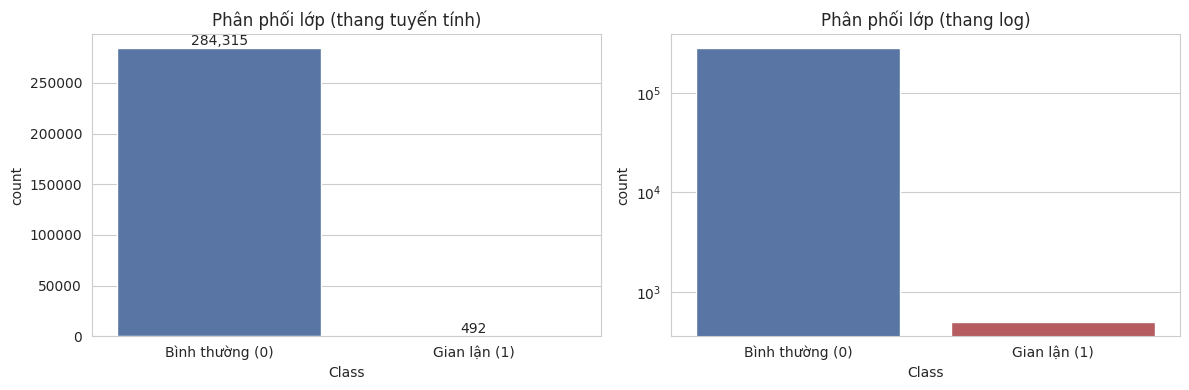

In [ ]:
class_counts = df['Class'].value_counts()
class_pct = df['Class'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Số lượng': class_counts, 'Tỷ lệ (%)': class_pct.round(4)}))
print(f"\nTỷ lệ mất cân bằng: 1 gian lận : {class_counts[0]/class_counts[1]:.0f} bình thường")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='Class', data=df, ax=ax[0], palette=['#4C72B0', '#C44E52'])
ax[0].set_title('Phân phối lớp (thang tuyến tính)')
ax[0].set_xticklabels(['Bình thường (0)', 'Gian lận (1)'])
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x()+p.get_width()/2, p.get_height()),
                   ha='center', va='bottom')

sns.countplot(x='Class', data=df, ax=ax[1], palette=['#4C72B0', '#C44E52'])
ax[1].set_yscale('log')
ax[1].set_title('Phân phối lớp (thang log)')
ax[1].set_xticklabels(['Bình thường (0)', 'Gian lận (1)'])
plt.tight_layout()
plt.show()

Cell 1.3: Phân tích Time và Amount

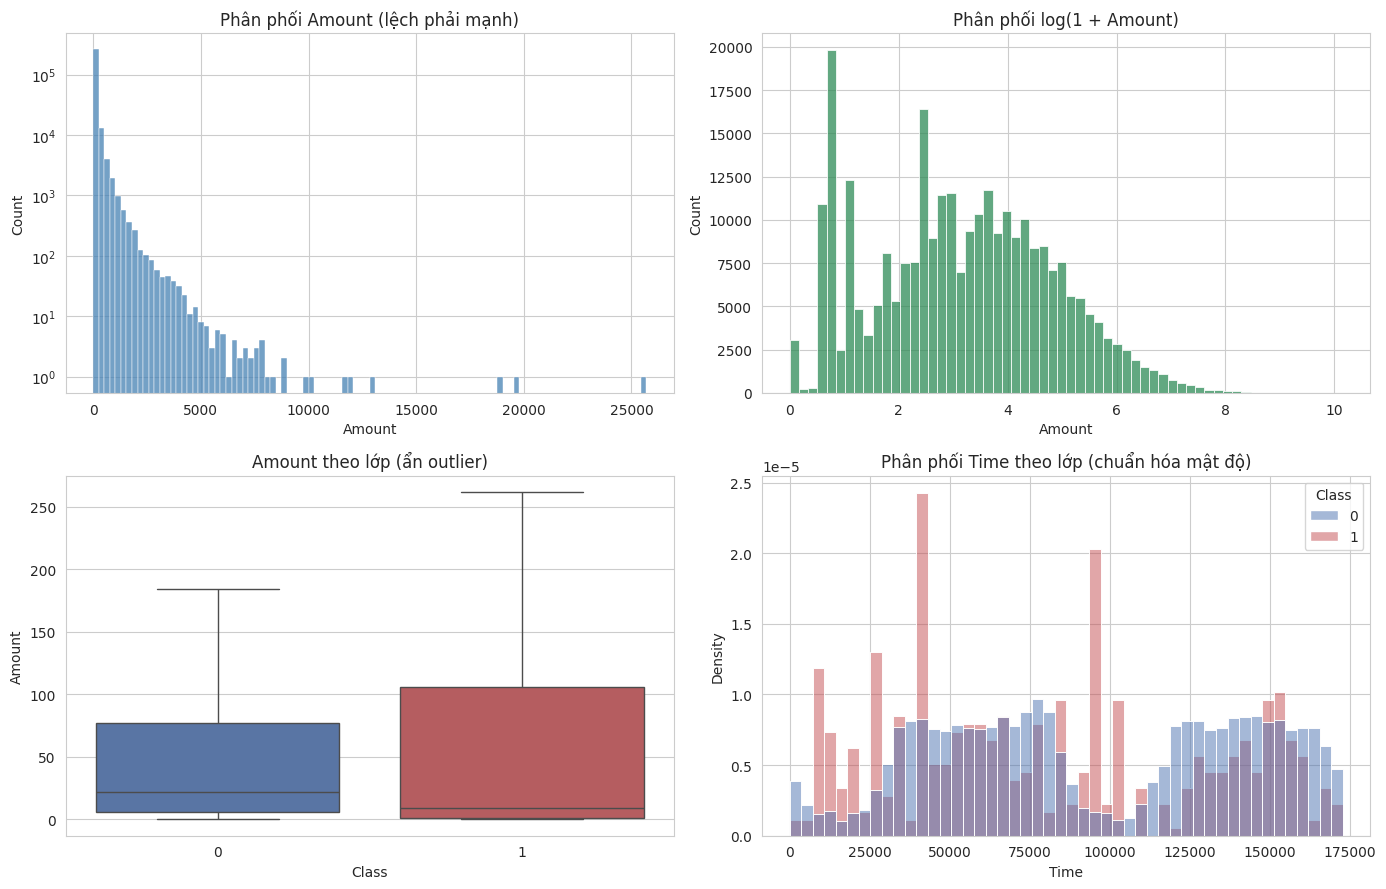

Amount theo lớp:


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# Amount
sns.histplot(df['Amount'], bins=100, ax=ax[0, 0], color='steelblue')
ax[0, 0].set_title('Phân phối Amount (lệch phải mạnh)')
ax[0, 0].set_yscale('log')

sns.histplot(np.log1p(df['Amount']), bins=60, ax=ax[0, 1], color='seagreen')
ax[0, 1].set_title('Phân phối log(1 + Amount)')

# Amount theo lớp
sns.boxplot(x='Class', y='Amount', data=df, ax=ax[1, 0], palette=['#4C72B0', '#C44E52'], showfliers=False)
ax[1, 0].set_title('Amount theo lớp (ẩn outlier)')

# Time theo lớp
sns.histplot(data=df, x='Time', hue='Class', bins=48, ax=ax[1, 1],
             stat='density', common_norm=False, palette=['#4C72B0', '#C44E52'])
ax[1, 1].set_title('Phân phối Time theo lớp (chuẩn hóa mật độ)')

plt.tight_layout()
plt.show()

print("Amount theo lớp:")
display(df.groupby('Class')['Amount'].describe())

Cell 1.4: Ma trận tương quan

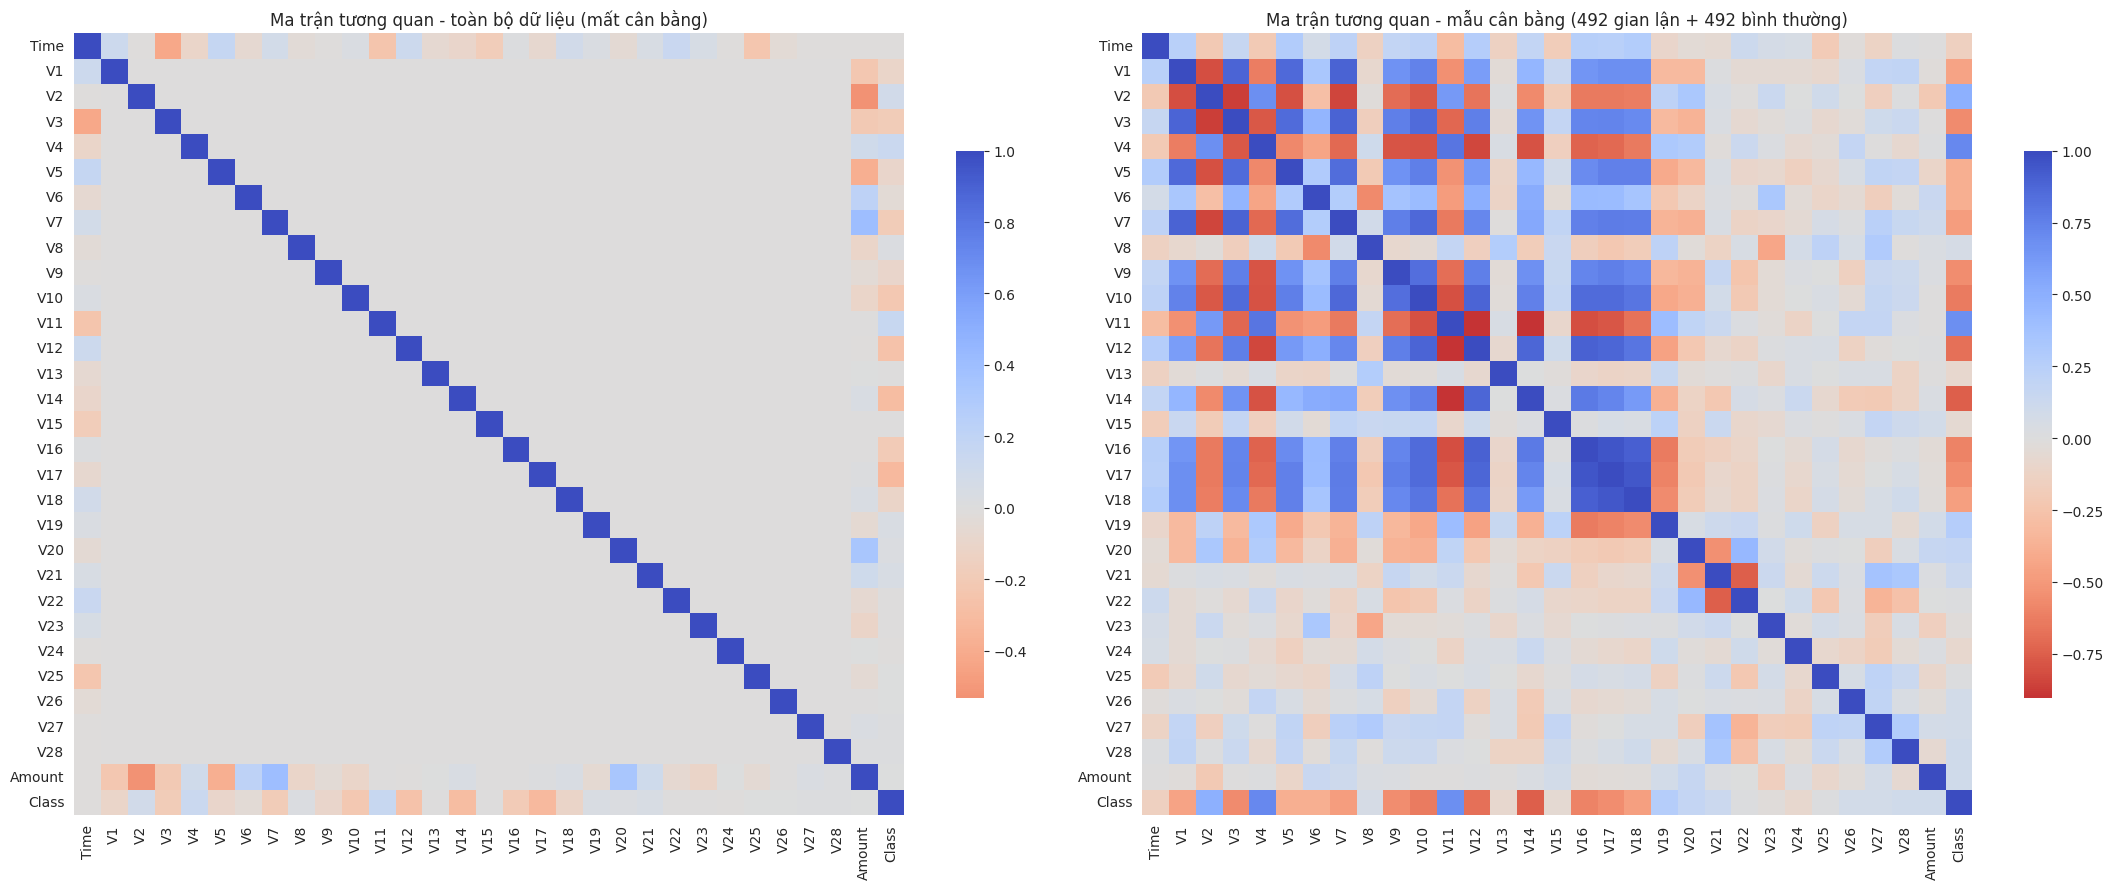

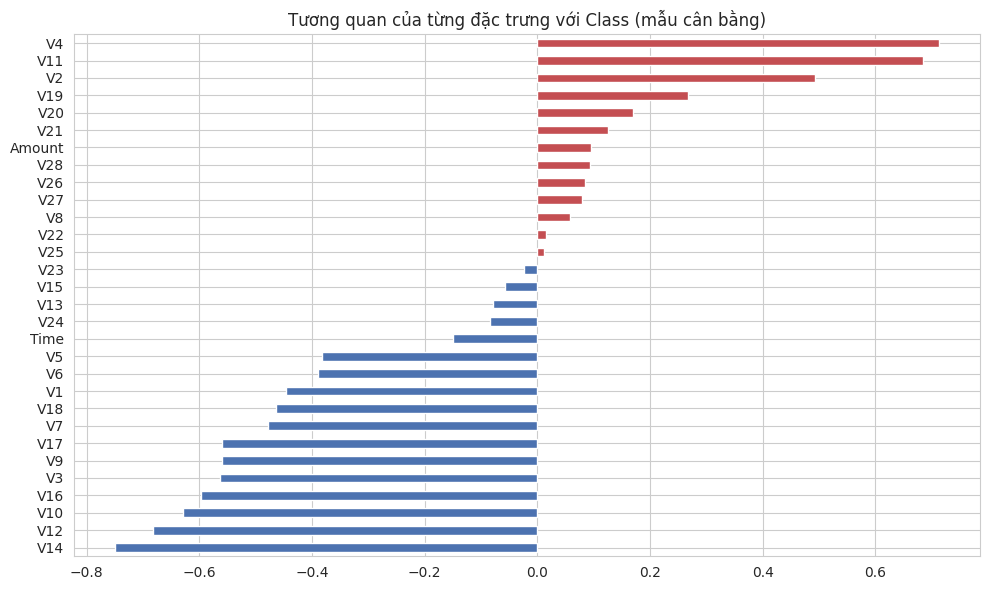

Top 5 tương quan dương:
 V20    0.169025
V19    0.267809
V2     0.491904
V11    0.685056
V4     0.712610
Name: Class, dtype: float64

Top 5 tương quan âm:
 V14   -0.749228
V12   -0.682039
V10   -0.628327
V16   -0.597790
V3    -0.564371
Name: Class, dtype: float64


In [ ]:
# (a) Trên toàn bộ dữ liệu
corr_full = df.corr()

# (b) Trên mẫu cân bằng (lấy toàn bộ gian lận + số lượng bằng nhau giao dịch bình thường)
fraud = df[df['Class'] == 1]
normal = df[df['Class'] == 0].sample(n=len(fraud), random_state=RANDOM_STATE)
df_balanced = pd.concat([fraud, normal])
corr_bal = df_balanced.corr()

fig, ax = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(corr_full, cmap='coolwarm_r', center=0, ax=ax[0], cbar_kws={'shrink': .7})
ax[0].set_title('Ma trận tương quan - toàn bộ dữ liệu (mất cân bằng)')
sns.heatmap(corr_bal, cmap='coolwarm_r', center=0, ax=ax[1], cbar_kws={'shrink': .7})
ax[1].set_title('Ma trận tương quan - mẫu cân bằng (492 gian lận + 492 bình thường)')
plt.tight_layout()
plt.show()

# Top đặc trưng tương quan với Class (trên mẫu cân bằng)
top_corr = corr_bal['Class'].drop('Class').sort_values()
plt.figure(figsize=(10, 6))
top_corr.plot(kind='barh', color=np.where(top_corr > 0, '#C44E52', '#4C72B0'))
plt.title('Tương quan của từng đặc trưng với Class (mẫu cân bằng)')
plt.tight_layout()
plt.show()

print("Top 5 tương quan dương:\n", top_corr.tail(5))
print("\nTop 5 tương quan âm:\n", top_corr.head(5))

PHẦN 2: Tiền xử lý và Luồng A

Thứ tự đúng để tránh rò rỉ dữ liệu (data leakage):
Làm sạch → Tạo đặc trưng (theo từng dòng) → Chia train/test → Fit scaler trên train → SMOTE chỉ trên train

Cell 2.1: Xử lý dữ liệu thiếu và trùng lặp

In [ ]:
df_clean = df.copy()

# Dữ liệu không có giá trị thiếu. Imputer vẫn được đưa vào pipeline (cell 2.4)
# để quy trình tổng quát và an toàn khi gặp dữ liệu mới.

# Loại bỏ dòng trùng lặp: tránh cùng một mẫu xuất hiện ở cả train và test
before = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Đã xóa {before - len(df_clean)} dòng trùng. Còn lại: {len(df_clean):,} dòng")
print("Phân phối lớp sau khi xóa trùng:")
print(df_clean['Class'].value_counts())

Đã xóa 1081 dòng trùng. Còn lại: 283,726 dòng
Phân phối lớp sau khi xóa trùng:
Class
0    283253
1       473
Name: count, dtype: int64


Cell 2.2: Tạo đặc trưng mới

In [ ]:
# 1) Hour: giờ trong ngày (Time là số giây kể từ giao dịch đầu tiên)
df_clean['Hour'] = (df_clean['Time'] // 3600) % 24

# 2) Mã hóa chu kỳ cho giờ: 23h và 0h phải "gần nhau"
df_clean['Hour_sin'] = np.sin(2 * np.pi * df_clean['Hour'] / 24)
df_clean['Hour_cos'] = np.cos(2 * np.pi * df_clean['Hour'] / 24)

# 3) Amount_log: giảm độ lệch phải của Amount
df_clean['Amount_log'] = np.log1p(df_clean['Amount'])

# Bỏ Time (giá trị tuyệt đối không có ý nghĩa tổng quát) và Hour (đã có sin/cos)
df_clean = df_clean.drop(columns=['Time', 'Hour'])

print("Các cột hiện có:", list(df_clean.columns))

Các cột hiện có: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class', 'Hour_sin', 'Hour_cos', 'Amount_log']


Cell 2.3: Chia train/test (phân tầng)

In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Tỷ lệ gian lận - train: {y_train.mean()*100:.4f}% | test: {y_test.mean()*100:.4f}%")

Train: (226980, 32), Test: (56746, 32)
Tỷ lệ gian lận - train: 0.1665% | test: 0.1674%


Cell 2.4: Chuẩn hóa (fit trên train, áp dụng cho test)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler

v_cols = [f'V{i}' for i in range(1, 29)]
robust_cols = ['Amount']                                   # nhiều outlier -> RobustScaler
standard_cols = v_cols + ['Amount_log', 'Hour_sin', 'Hour_cos']

preprocessor = ColumnTransformer(
    transformers=[
        ('robust', Pipeline([('imputer', SimpleImputer(strategy='median')),
                             ('scaler', RobustScaler())]), robust_cols),
        ('standard', Pipeline([('imputer', SimpleImputer(strategy='median')),
                               ('scaler', StandardScaler())]), standard_cols),
    ],
    remainder='drop',
    verbose_feature_names_out=False
).set_output(transform='pandas')

X_train_scaled = preprocessor.fit_transform(X_train)   # chỉ fit trên train
X_test_scaled = preprocessor.transform(X_test)         # test chỉ transform

print("Số đặc trưng sau tiền xử lý:", X_train_scaled.shape[1])
display(X_train_scaled[['Amount', 'Amount_log', 'V1', 'Hour_sin']].describe().T.round(3))

Số đặc trưng sau tiền xử lý: 32


,count,mean,std,min,25%,50%,75%,max
Amount,226980.0,0.919,3.406,-0.306,-0.227,0.000,0.773,272.096
Amount_log,226980.0,-0.000,1.000,-1.906,-0.758,-0.010,0.731,4.063
V1,226980.0,0.000,1.000,-28.970,-0.473,0.007,0.673,1.258
Hour_sin,226980.0,0.000,1.000,-1.161,-0.955,-0.393,0.774,1.914


Cell 2.5: Cân bằng dữ liệu bằng SMOTE (chỉ trên tập train)

Trước SMOTE: {0: np.int64(226602), 1: np.int64(378)}
Sau SMOTE : {0: np.int64(226602), 1: np.int64(226602)}
Kích thước X_train_A: (453204, 32)


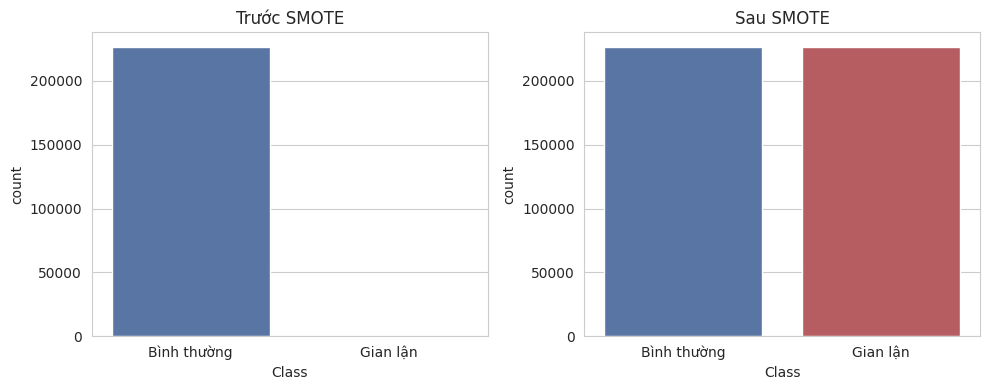

In [ ]:
from imblearn.over_sampling import SMOTE

print("Trước SMOTE:", dict(y_train.value_counts()))

smote = SMOTE(random_state=RANDOM_STATE)   # mặc định: cân bằng 1:1
X_train_A, y_train_A = smote.fit_resample(X_train_scaled, y_train)

print("Sau SMOTE :", dict(pd.Series(y_train_A).value_counts()))
print("Kích thước X_train_A:", X_train_A.shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (labels, title) in zip(ax, [(y_train, 'Trước SMOTE'), (y_train_A, 'Sau SMOTE')]):
    sns.countplot(x=labels, ax=a, palette=['#4C72B0', '#C44E52'])
    a.set_title(title)
    a.set_xticklabels(['Bình thường', 'Gian lận'])
plt.tight_layout()
plt.show()

Cell 2.6: Lưu dữ liệu để dùng cho Phần 3 và 4

In [ ]:
import joblib

data_pack = {
    # Luồng A (đã SMOTE)
    'X_train_A': X_train_A.astype('float32'),
    'y_train_A': np.asarray(y_train_A),
    # Dữ liệu đã chuẩn hóa, chưa SMOTE (dùng cho Autoencoder ở Luồng B)
    'X_train_scaled': X_train_scaled.astype('float32'),
    'y_train': y_train.values,
    # Tập test (dùng chung cho cả hai luồng)
    'X_test_scaled': X_test_scaled.astype('float32'),
    'y_test': y_test.values,
    'feature_names': list(X_train_scaled.columns),
}
joblib.dump(data_pack, '/content/drive/MyDrive/ccfraud_data_pack.joblib')
print("Đã lưu. Số đặc trưng:", len(data_pack['feature_names']))

Đã lưu. Số đặc trưng: 32


PHẦN 3: Autoencoder cho Luồng B

Autoencoder học không giám sát: đầu vào và đầu ra đều là X, nên nhãn không bị dùng khi huấn luyện. Nó chỉ được fit trên tập train đã chuẩn hóa, chưa SMOTE.

Cell 3.1: Nạp dữ liệu và cấu hình

In [ ]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

data = joblib.load('/content/drive/MyDrive/ccfraud_data_pack.joblib')
X_train = np.asarray(data['X_train_scaled'], dtype='float32')
X_test  = np.asarray(data['X_test_scaled'],  dtype='float32')
y_train, y_test = data['y_train'], data['y_test']

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

# --- Cấu hình ---
LATENT_DIM = 8                    # kích thước bottleneck (nên thử 4, 8, 16)
TRAIN_ON_NORMAL_ONLY = False      # False: dùng toàn bộ train | True: chỉ giao dịch bình thường
X_ae_train = X_train[y_train == 0] if TRAIN_ON_NORMAL_ONLY else X_train
print("Dữ liệu huấn luyện Autoencoder:", X_ae_train.shape)

X_train: (226980, 32) | X_test: (56746, 32)
Dữ liệu huấn luyện Autoencoder: (226980, 32)


Cell 3.2: Xây dựng kiến trúc

In [ ]:
def build_autoencoder(input_dim, latent_dim):
    inputs = keras.Input(shape=(input_dim,), name='input')

    # ---- Encoder ----
    x = layers.Dense(24, name='enc_1')(inputs)
    x = layers.LeakyReLU(0.1)(x)
    x = layers.Dense(16, name='enc_2')(x)
    x = layers.LeakyReLU(0.1)(x)

    # ---- Bottleneck / Latent space ----
    latent = layers.Dense(latent_dim, name='bottleneck')(x)

    # ---- Decoder (đối xứng với Encoder) ----
    x = layers.Dense(16, name='dec_1')(latent)
    x = layers.LeakyReLU(0.1)(x)
    x = layers.Dense(24, name='dec_2')(x)
    x = layers.LeakyReLU(0.1)(x)
    outputs = layers.Dense(input_dim, name='output')(x)   # tuyến tính vì dữ liệu đã chuẩn hóa (có giá trị âm)

    autoencoder = keras.Model(inputs, outputs, name='autoencoder')
    encoder = keras.Model(inputs, latent, name='encoder')  # dùng chung layer với autoencoder
    return autoencoder, encoder

autoencoder, encoder = build_autoencoder(X_ae_train.shape[1], LATENT_DIM)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_1 (Dense)                   │ (None, 24)             │           792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_2 (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_2 (Dense)                   │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 32)             │           800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,680 (10.47 KB)

 Trainable params: 2,680 (10.47 KB)

 Non-trainable params: 0 (0.00 B)

Cell 3.3: Huấn luyện

Epoch 1/100
798/798 - 4s - 5ms/step - loss: 0.7715 - val_loss: 0.6104 - learning_rate: 0.0010
Epoch 2/100
798/798 - 2s - 3ms/step - loss: 0.5620 - val_loss: 0.5063 - learning_rate: 0.0010
Epoch 3/100
798/798 - 4s - 5ms/step - loss: 0.4892 - val_loss: 0.4617 - learning_rate: 0.0010
Epoch 4/100
798/798 - 3s - 3ms/step - loss: 0.4565 - val_loss: 0.4373 - learning_rate: 0.0010
Epoch 5/100
798/798 - 2s - 2ms/step - loss: 0.4326 - val_loss: 0.4154 - learning_rate: 0.0010
Epoch 6/100
798/798 - 2s - 3ms/step - loss: 0.4141 - val_loss: 0.4021 - learning_rate: 0.0010
Epoch 7/100
798/798 - 2s - 3ms/step - loss: 0.4025 - val_loss: 0.3933 - learning_rate: 0.0010
Epoch 8/100
798/798 - 2s - 3ms/step - loss: 0.3938 - val_loss: 0.3861 - learning_rate: 0.0010
Epoch 9/100
798/798 - 3s - 3ms/step - loss: 0.3870 - val_loss: 0.3796 - learning_rate: 0.0010
Epoch 10/100
798/798 - 4s - 5ms/step - loss: 0.3805 - val_loss: 0.3734 - learning_rate: 0.0010
Epoch 11/100
798/798 - 2s - 2ms/step - loss: 0.3745 - val_l

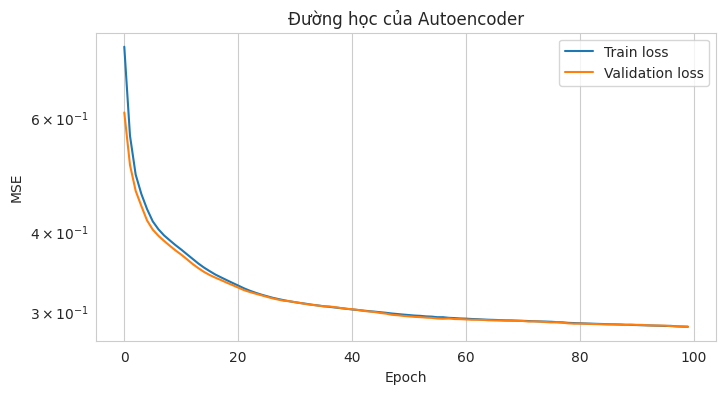

In [ ]:
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='mse')

cbs = [
    callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5),
]

history = autoencoder.fit(
    X_ae_train, X_ae_train,          # đầu vào = đầu ra
    epochs=100,
    batch_size=256,
    validation_split=0.1,
    shuffle=True,
    callbacks=cbs,
    verbose=2
)

plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.yscale('log')
plt.title('Đường học của Autoencoder'); plt.legend(); plt.show()

Cell 3.4: Kiểm tra chất lượng tái tạo (tùy chọn nhưng nên có)

MSE tái tạo trung bình - bình thường: 0.2841
MSE tái tạo trung bình - gian lận   : 1.9300


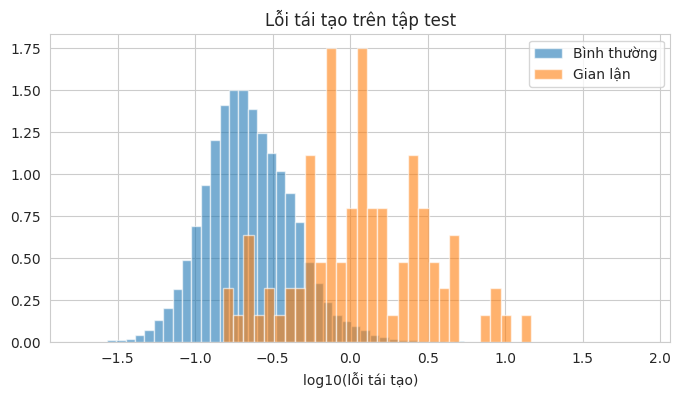

In [ ]:
recon = autoencoder.predict(X_test, batch_size=1024, verbose=0)
recon_err = np.mean((X_test - recon) ** 2, axis=1)

print(f"MSE tái tạo trung bình - bình thường: {recon_err[y_test == 0].mean():.4f}")
print(f"MSE tái tạo trung bình - gian lận   : {recon_err[y_test == 1].mean():.4f}")

plt.figure(figsize=(8, 4))
plt.hist(np.log10(recon_err[y_test == 0] + 1e-8), bins=60, alpha=.6, density=True, label='Bình thường')
plt.hist(np.log10(recon_err[y_test == 1] + 1e-8), bins=30, alpha=.6, density=True, label='Gian lận')
plt.xlabel('log10(lỗi tái tạo)'); plt.legend(); plt.title('Lỗi tái tạo trên tập test')
plt.show()

Cell 3.5: Trích xuất Encoder và tạo bộ đặc trưng Luồng B

In [ ]:
# Chỉ giữ Encoder: đưa dữ liệu qua và lấy vector tại bottleneck
Z_train = encoder.predict(X_train, batch_size=1024, verbose=0)   # toàn bộ train (kể cả gian lận)
Z_test  = encoder.predict(X_test,  batch_size=1024, verbose=0)

print("Z_train:", Z_train.shape, "| Z_test:", Z_test.shape)   # (n, 8)

# Lưu lại
encoder.save('/content/drive/MyDrive/ccfraud_encoder.keras')
joblib.dump({'Z_train': Z_train, 'Z_test': Z_test, 'latent_dim': LATENT_DIM},
            '/content/drive/MyDrive/ccfraud_flowB.joblib')

Z_train: (226980, 8) | Z_test: (56746, 8)


['/content/drive/MyDrive/ccfraud_flowB.joblib']

Cell 3.6 (tùy chọn): Thí nghiệm kích thước bottleneck

In [ ]:
rows = []
for d in [4, 8, 16]:
    ae, _ = build_autoencoder(X_ae_train.shape[1], d)
    ae.compile(optimizer='adam', loss='mse')
    h = ae.fit(X_ae_train, X_ae_train, epochs=50, batch_size=256, validation_split=0.1,
               callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
    rows.append({'latent_dim': d, 'best_val_mse': min(h.history['val_loss'])})
display(pd.DataFrame(rows))

,latent_dim,best_val_mse
0,4,0.440747
1,8,0.297885
2,16,0.205951


PHẦN 4: Huấn luyện và đánh giá trên cả 2 luồng

Mình thêm Logistic Regression làm mô hình cơ sở (baseline) bên cạnh Random Forest và XGBoost. Luồng A đã cân bằng bằng SMOTE nên không dùng trọng số lớp. Luồng B không có SMOTE nên dùng class_weight / scale_pos_weight để xử lý mất cân bằng.

Cell 4.1: Nạp dữ liệu và khai báo luồng

In [ ]:
import time
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             roc_curve, precision_recall_curve)

RANDOM_STATE = 42
data = joblib.load('/content/drive/MyDrive/ccfraud_data_pack.joblib')
flowB = joblib.load('/content/drive/MyDrive/ccfraud_flowB.joblib')

y_train, y_test = data['y_train'], data['y_test']
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

FLOWS = {
    'Luồng A': dict(X_tr=data['X_train_A'], y_tr=data['y_train_A'],
                    X_te=data['X_test_scaled'], use_weight=False),   # đã SMOTE
    'Luồng B': dict(X_tr=flowB['Z_train'], y_tr=y_train,
                    X_te=flowB['Z_test'], use_weight=True),          # Autoencoder + trọng số lớp
}

def make_models(use_weight):
    return {
        'Logistic Regression': LogisticRegression(
            max_iter=1000, class_weight='balanced' if use_weight else None,
            random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(
            n_estimators=100, min_samples_leaf=2, n_jobs=-1,
            class_weight='balanced_subsample' if use_weight else None,
            random_state=RANDOM_STATE),
        'XGBoost': XGBClassifier(
            n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
            colsample_bytree=0.8, tree_method='hist', eval_metric='aucpr',
            scale_pos_weight=neg_pos_ratio if use_weight else 1,
            n_jobs=-1, random_state=RANDOM_STATE),
    }

Cell 4.2: Huấn luyện và đánh giá

In [ ]:
results, cms, probas = [], {}, {}

for flow_name, f in FLOWS.items():
    for model_name, model in make_models(f['use_weight']).items():
        t0 = time.time()
        model.fit(f['X_tr'], f['y_tr'])
        fit_time = time.time() - t0

        y_pred = model.predict(f['X_te'])
        y_prob = model.predict_proba(f['X_te'])[:, 1]

        print(f"\n{'='*60}\n{flow_name} | {model_name}  (huấn luyện {fit_time:.1f}s)\n{'='*60}")
        print(classification_report(y_test, y_pred, target_names=['Bình thường', 'Gian lận'], digits=4))

        results.append({
            'Luồng': flow_name, 'Mô hình': model_name,
            'Precision': precision_score(y_test, y_pred),
            'Recall': recall_score(y_test, y_pred),
            'F1': f1_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_prob),
            'PR-AUC': average_precision_score(y_test, y_prob),
            'Thời gian (s)': round(fit_time, 1),
        })
        cms[(flow_name, model_name)] = confusion_matrix(y_test, y_pred)
        probas[(flow_name, model_name)] = y_prob

results_df = pd.DataFrame(results)
display(results_df.round(4))


Luồng A | Logistic Regression  (huấn luyện 7.0s)
              precision    recall  f1-score   support

 Bình thường     0.9998    0.9741    0.9868     56651
    Gian lận     0.0535    0.8737    0.1008        95

    accuracy                         0.9739     56746
   macro avg     0.5266    0.9239    0.5438     56746
weighted avg     0.9982    0.9739    0.9853     56746


Luồng A | Random Forest  (huấn luyện 493.6s)
              precision    recall  f1-score   support

 Bình thường     0.9996    0.9999    0.9997     56651
    Gian lận     0.9231    0.7579    0.8324        95

    accuracy                         0.9995     56746
   macro avg     0.9613    0.8789    0.9161     56746
weighted avg     0.9995    0.9995    0.9995     56746


Luồng A | XGBoost  (huấn luyện 27.0s)
              precision    recall  f1-score   support

 Bình thường     0.9996    0.9999    0.9998     56651
    Gian lận     0.9241    0.7684    0.8391        95

    accuracy                         0.9995    

,Luồng,Mô hình,Precision,Recall,F1,ROC-AUC,PR-AUC,Thời gian (s)
0,Luồng A,Logistic Regression,0.0535,0.8737,0.1008,0.9614,0.6864,7.0
1,Luồng A,Random Forest,0.9231,0.7579,0.8324,0.9630,0.8114,493.6
2,Luồng A,XGBoost,0.9241,0.7684,0.8391,0.9756,0.8122,27.0
3,Luồng B,Logistic Regression,0.0297,0.7895,0.0572,0.9287,0.5499,1.0
4,Luồng B,Random Forest,0.9577,0.7158,0.8193,0.9183,0.8014,83.0
5,Luồng B,XGBoost,0.8276,0.7579,0.7912,0.9389,0.7728,8.3


Cell 4.3: Confusion Matrix

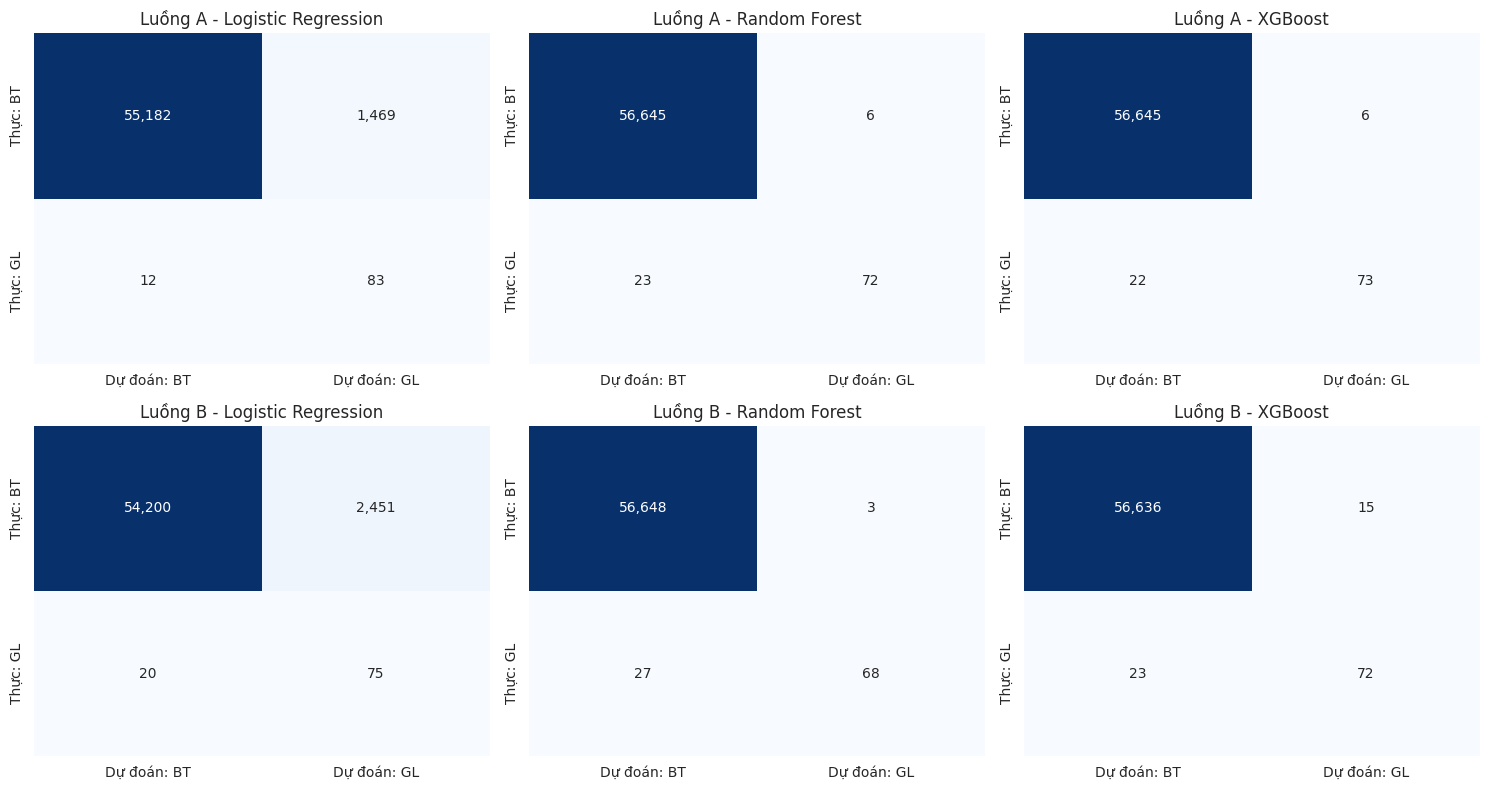

In [ ]:
model_names = ['Logistic Regression', 'Random Forest', 'XGBoost']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, flow_name in enumerate(FLOWS):
    for j, m in enumerate(model_names):
        sns.heatmap(cms[(flow_name, m)], annot=True, fmt=',d', cmap='Blues', cbar=False,
                    xticklabels=['Dự đoán: BT', 'Dự đoán: GL'],
                    yticklabels=['Thực: BT', 'Thực: GL'], ax=axes[i, j])
        axes[i, j].set_title(f'{flow_name} - {m}')
plt.tight_layout(); plt.show()

Cell 4.4: Đường ROC và Precision-Recall

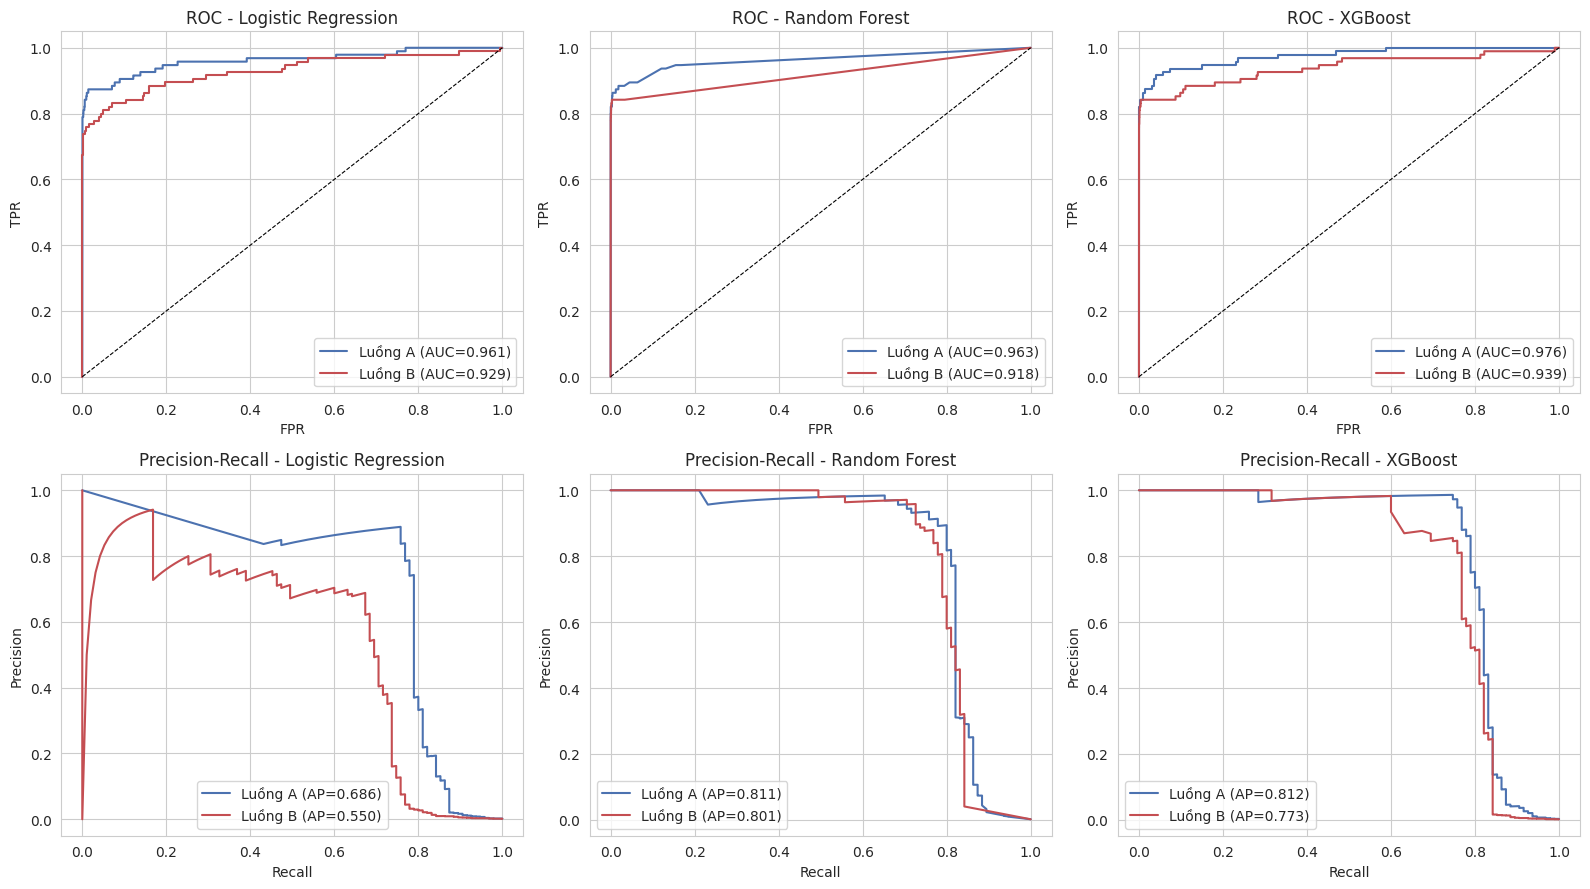

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
colors = {'Luồng A': '#4C72B0', 'Luồng B': '#C44E52'}
for j, m in enumerate(model_names):
    for flow_name in FLOWS:
        p = probas[(flow_name, m)]
        fpr, tpr, _ = roc_curve(y_test, p)
        pr, rc, _ = precision_recall_curve(y_test, p)
        row = results_df[(results_df['Luồng'] == flow_name) & (results_df['Mô hình'] == m)].iloc[0]
        axes[0, j].plot(fpr, tpr, color=colors[flow_name], label=f"{flow_name} (AUC={row['ROC-AUC']:.3f})")
        axes[1, j].plot(rc, pr, color=colors[flow_name], label=f"{flow_name} (AP={row['PR-AUC']:.3f})")
    axes[0, j].plot([0, 1], [0, 1], 'k--', lw=.8)
    axes[0, j].set_title(f'ROC - {m}'); axes[0, j].set_xlabel('FPR'); axes[0, j].set_ylabel('TPR')
    axes[1, j].set_title(f'Precision-Recall - {m}'); axes[1, j].set_xlabel('Recall'); axes[1, j].set_ylabel('Precision')
    axes[0, j].legend(); axes[1, j].legend()
plt.tight_layout(); plt.show()

Cell 4.5: Bảng và biểu đồ so sánh tổng hợp

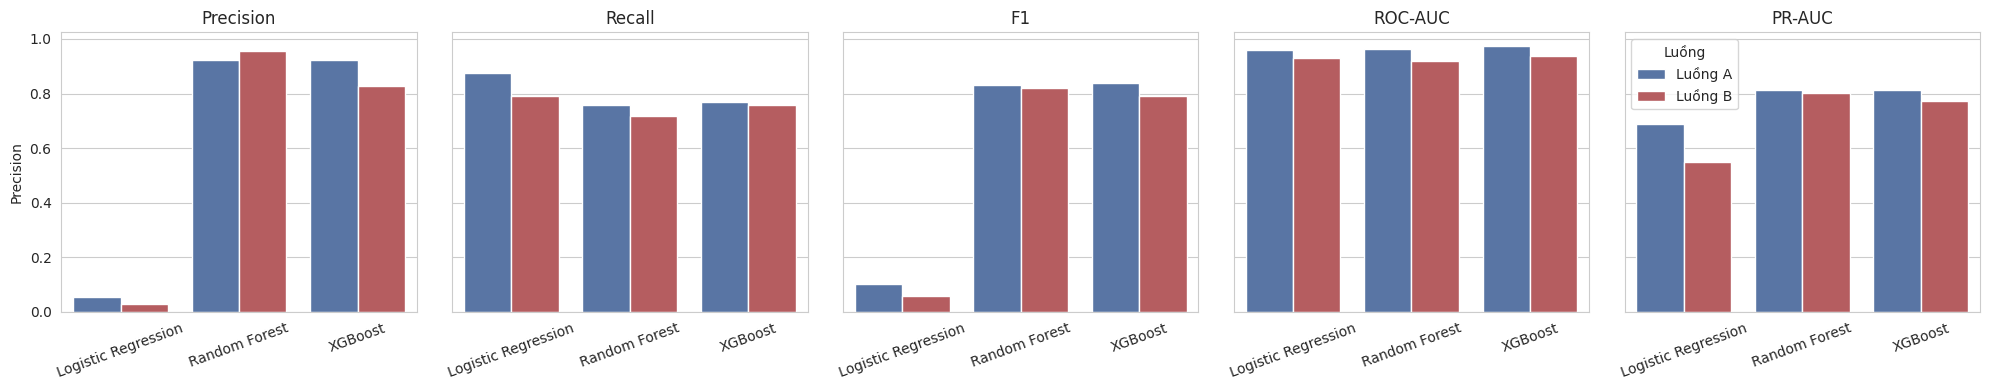

\begin{tabular}{llrrrrrr}
\toprule
Luồng & Mô hình & Precision & Recall & F1 & ROC-AUC & PR-AUC & Thời gian (s) \\
\midrule
Luồng A & Logistic Regression & 0.0535 & 0.8737 & 0.1008 & 0.9614 & 0.6864 & 7.0000 \\
Luồng A & Random Forest & 0.9231 & 0.7579 & 0.8324 & 0.9630 & 0.8114 & 493.6000 \\
Luồng A & XGBoost & 0.9241 & 0.7684 & 0.8391 & 0.9756 & 0.8122 & 27.0000 \\
Luồng B & Logistic Regression & 0.0297 & 0.7895 & 0.0572 & 0.9287 & 0.5499 & 1.0000 \\
Luồng B & Random Forest & 0.9577 & 0.7158 & 0.8193 & 0.9183 & 0.8014 & 83.0000 \\
Luồng B & XGBoost & 0.8276 & 0.7579 & 0.7912 & 0.9389 & 0.7728 & 8.3000 \\
\bottomrule
\end{tabular}



In [ ]:
metrics = ['Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
for ax, met in zip(axes, metrics):
    sns.barplot(data=results_df, x='Mô hình', y=met, hue='Luồng', palette=colors, ax=ax)
    ax.set_title(met); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=20)
    if ax is not axes[-1]: ax.get_legend().remove()
plt.tight_layout(); plt.show()

# Xuất bảng sang LaTeX để dán vào báo cáo
print(results_df.round(4).to_latex(index=False, float_format="%.4f"))
results_df.to_csv('/content/drive/MyDrive/ccfraud_results.csv', index=False)

In [ ]:
import joblib
from xgboost import XGBClassifier

neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()
params = dict(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
              colsample_bytree=0.8, tree_method='hist', eval_metric='aucpr',
              n_jobs=-1, random_state=42)

xgb_A = XGBClassifier(**params).fit(data['X_train_A'], data['y_train_A'])
xgb_B = XGBClassifier(scale_pos_weight=neg_pos_ratio, **params).fit(flowB['Z_train'], data['y_train'])

joblib.dump(preprocessor, '/content/drive/MyDrive/preprocessor.joblib')
joblib.dump(xgb_A, '/content/drive/MyDrive/model_A_xgb.joblib')
joblib.dump(xgb_B, '/content/drive/MyDrive/model_B_xgb.joblib')

['/content/drive/MyDrive/model_B_xgb.joblib']

In [ ]:
# ===== CELL XUẤT ARTIFACTS CHO ỨNG DỤNG (chạy trên Google Colab) =====
# Cần có sẵn trên Google Drive (đã tạo ở các phần trước):
#   creditcard.csv, ccfraud_data_pack.joblib, ccfraud_flowB.joblib, ccfraud_encoder.keras,
#   ccfraud_results.csv, preprocessor.joblib, model_A_xgb.joblib, model_B_xgb.joblib
import json, shutil, datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import xgboost
import sklearn
from sklearn.model_selection import train_test_split

DRIVE = '/content/drive/MyDrive/'
RANDOM_STATE = 42
OUT = Path(DRIVE + 'ccfraud_app/artifacts')
OUT.mkdir(parents=True, exist_ok=True)

# ---- 1. Nạp lại các đối tượng đã lưu ----
data = joblib.load(DRIVE + 'ccfraud_data_pack.joblib')
flowB = joblib.load(DRIVE + 'ccfraud_flowB.joblib')
preprocessor = joblib.load(DRIVE + 'preprocessor.joblib')
xgb_A = joblib.load(DRIVE + 'model_A_xgb.joblib')
xgb_B = joblib.load(DRIVE + 'model_B_xgb.joblib')
from tensorflow import keras
encoder = keras.models.load_model(DRIVE + 'ccfraud_encoder.keras')

# ---- 2. Bộ chuẩn hóa -> JSON (không phụ thuộc phiên bản scikit-learn) ----
rob = preprocessor.named_transformers_['robust']
std = preprocessor.named_transformers_['standard']
features = list(preprocessor.get_feature_names_out())
scaler = {
    'features': features,
    'robust': {
        'cols': list(preprocessor.transformers_[0][2]),
        'imputer': rob.named_steps['imputer'].statistics_.tolist(),
        'center': rob.named_steps['scaler'].center_.tolist(),
        'scale': rob.named_steps['scaler'].scale_.tolist(),
    },
    'standard': {
        'cols': list(preprocessor.transformers_[1][2]),
        'imputer': std.named_steps['imputer'].statistics_.tolist(),
        'mean': std.named_steps['scaler'].mean_.tolist(),
        'scale': std.named_steps['scaler'].scale_.tolist(),
    },
}
assert scaler['robust']['cols'] + scaler['standard']['cols'] == features, 'Thứ tự cột không khớp'
assert list(data['X_train_A'].columns) == features, 'Thứ tự đặc trưng Luồng A không khớp'
(OUT / 'scaler.json').write_text(json.dumps(scaler, ensure_ascii=False, indent=1), encoding='utf-8')

# ---- 3. XGBoost -> JSON (định dạng ổn định giữa các phiên bản) ----
for name, model in [('A', xgb_A), ('B', xgb_B)]:
    booster = model.get_booster()
    booster.feature_names = None
    booster.save_model(str(OUT / f'model_{name}.json'))

# ---- 4. Encoder -> trọng số numpy ----
ws = encoder.get_weights()          # W1, b1, W2, b2, W3, b3
assert len(ws) == 6, 'Encoder phải có đúng 3 lớp Dense'
np.savez(OUT / 'encoder_weights.npz', W1=ws[0], b1=ws[1], W2=ws[2], b2=ws[3], W3=ws[4], b3=ws[5])

# ---- 5. Điểm dự đoán trên tập test thật (dùng cho trang "Đánh giá mô hình") ----
y_test = np.asarray(data['y_test'])
proba_A = xgb_A.predict_proba(data['X_test_scaled'])[:, 1]
proba_B = xgb_B.predict_proba(flowB['Z_test'])[:, 1]
pd.DataFrame({'y_true': y_test, 'proba_A': proba_A, 'proba_B': proba_B}).to_csv(
    OUT / 'test_scores.csv', index=False)

# ---- 6. Mẫu demo: các giao dịch THÔ của tập test (95 gian lận + 3000 bình thường) ----
df = pd.read_csv(DRIVE + 'creditcard.csv')
df_nodup = df.drop_duplicates().reset_index(drop=True)
_, idx_test = train_test_split(df_nodup.index, test_size=0.2,
                               stratify=df_nodup['Class'], random_state=RANDOM_STATE)
raw_test = df_nodup.loc[idx_test].reset_index(drop=True)
assert (raw_test['Class'].values == y_test).all(), 'Không khớp tập test, hãy kiểm tra lại bước chia dữ liệu'
rng = np.random.default_rng(RANDOM_STATE)
fraud_idx = np.where(y_test == 1)[0]
normal_idx = rng.choice(np.where(y_test == 0)[0], size=3000, replace=False)
sel = rng.permutation(np.r_[fraud_idx, normal_idx])
demo = raw_test.loc[sel].copy()
demo['ref_proba_A'] = proba_A[sel]      # xác suất tham chiếu từ scikit-learn/Keras để kiểm tra
demo['ref_proba_B'] = proba_B[sel]
demo.to_csv(OUT / 'demo_sample.csv', index=False)

# ---- 7. Độ quan trọng đặc trưng (Luồng A) và bảng kết quả ----
pd.DataFrame({'feature': features, 'importance': xgb_A.feature_importances_}).sort_values(
    'importance', ascending=False).to_csv(OUT / 'feature_importance_A.csv', index=False)
shutil.copy(DRIVE + 'ccfraud_results.csv', OUT / 'results.csv')

# ---- 8. Thông tin chung ----
meta = {
    'created': datetime.date.today().isoformat(),
    'latent_dim': int(flowB.get('latent_dim', ws[4].shape[1])),
    'n_features': len(features),
    'n_test': int(len(y_test)),
    'n_test_fraud': int(y_test.sum()),
    'random_state': RANDOM_STATE,
    'trained_with': {'xgboost': xgboost.__version__, 'sklearn': sklearn.__version__},
}
(OUT / 'meta.json').write_text(json.dumps(meta, indent=1), encoding='utf-8')

zip_path = shutil.make_archive(DRIVE + 'ccfraud_artifacts', 'zip', OUT)
print('Đã tạo thư mục:', OUT)
print('Đã nén:', zip_path)
print(sorted(p.name for p in OUT.iterdir()))

Đã tạo thư mục: /content/drive/MyDrive/ccfraud_app/artifacts
Đã nén: /content/drive/MyDrive/ccfraud_artifacts.zip
['demo_sample.csv', 'encoder_weights.npz', 'feature_importance_A.csv', 'meta.json', 'model_A.json', 'model_B.json', 'results.csv', 'scaler.json', 'test_scores.csv']
